---
# Cuaderno 1: Analysis of TCGA database
---
Author: Melissa Ormeño

Laboratory: Cancer Molecular Dynamics

Date: Mayo 2026



In [13]:
import gzip
import io
import json
import pandas as pd
import requests
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt

import matplotlib
import matplotlib as mpl

## Extracting mutations from the TCGA (MAF file)

In [4]:


# Gene panels
gen_list = ['BMPR1B', 'ACVR2A', 'BMPR1A', 'ACVR1B', 'TGFBR1', 'ACVRL1','TGFBR2', 'ACVR1', 'ACVR2B', 'BMPR2', 'AMHR2', 'ACVR1C']

# TCGA projects
projects_gdc = {
    "TCGA-BRCA": "Breast",
    "TCGA-LUAD": "Bronchus and lung",
    "TCGA-LUSC": "Bronchus and lung",
    "TCGA-KIRC": "Kidney",
    "TCGA-KIRP": "Kidney",
    "TCGA-BLCA": "Bladder",
    "TCGA-COAD": "Colon",
    "TCGA-READ": "Rectum",
    "TCGA-STAD": "Stomach",
    "TCGA-LGG":  "Brain",
    "TCGA-GBM":  "Brain",
    "TCGA-UCEC": "Uterus",
    "TCGA-UCS":  "Uterus",
    "TCGA-OV":   "Ovary",
    "TCGA-LIHC": "Liver and intrahepatic bile ducts",
    "TCGA-PAAD": "Pancreas",
    "TCGA-ESCA": "Esophagus",
    "TCGA-THCA": "Thyroid gland",
    "TCGA-SKCM": "Skin"
}

ssm_endpt = "https://api.gdc.cancer.gov/ssms"
mut_list = []

print(
    f"Launching a query in the TCGA database: {len(projects_gdc)} projects and {len(gen_list)} genes"
)
for idx, project in enumerate(projects_gdc, 1):
    filters = {
        "op": "and",
        "content": [
            {"op": "in", "content": {"field": "consequence.transcript.gene.symbol", "value": gen_list}},
            {"op": "in", "content": {"field": "occurrence.case.project.project_id", "value": [project]}},
        ],
    }

    fields = [
        "ssm_id",
        "chromosome",
        "genomic_dna_change",  
        "mutation_subtype",  # SNP, INS, DEL
        "ncbi_build",
        "reference_allele",  # Allele reference
        "tumor_allele",  # mutate allele
        "consequence.transcript.gene.symbol",
        "consequence.transcript.aa_change",  # Change aminoacid 
        "consequence.transcript.hgvsp",  
        "consequence.transcript.annotation.vep_impact",
        "consequence.transcript.consequence_type",  
        "occurrence.case.submitter_id",  
        "occurrence.case.project.project_id",
    ]

    params = {
        "filters": json.dumps(filters),
        "fields": ",".join(fields),
        "format": "JSON",
        "size": "2000",  
    }

    try:
        response = requests.get(ssm_endpt, params=params)
        data = response.json()
        hits = data.get("data", {}).get("hits", [])
    except Exception as e:
        print(f"   Error connecting to the project {project}: {e}")
        continue

    if not hits:
        continue

    for hit in hits:
        gene_symbol = hit.get("consequence", [{}])[0].get("transcript", {}).get("gene", {}).get("symbol", "Unknown")
        aa_change = hit.get("consequence", [{}])[0].get("transcript", {}).get("aa_change", "p.?")
        transcript_info = hit.get("consequence", [{}])[0].get("transcript", {})
        aa_long = transcript_info.get("hgvsp", "p.?")
       
        raw_efect = hit.get("consequence", [{}])[0].get("transcript", {}).get("consequence_type", "Unknown")
        efect_maf = raw_efect.replace("_variant", "_Mutation").capitalize()
        if "missense" in raw_efect:
            efect_maf = "Missense_Mutation"
        elif "synonymous" in raw_efect:
            efect_maf = "Silent"
        elif "stop_gained" in raw_efect:
            efect_maf = "Nonsense_Mutation"
        
        # Un mismo cambio puede reportarse en múltiples muestras/pacientes de ese proyecto
        for occ in hit.get("occurrence", []):
            patient_id = occ.get("case", {}).get("submitter_id", "Unknown")
            proj_id = occ.get("case", {}).get("project", {}).get("project_id", project)

            registro = {
                "Patient_ID": patient_id,
                "Tumor_Sample_Barcode": f"{patient_id}-TUMOR", 
                "Hugo_Symbol": gene_symbol,
                "Chromosome": hit.get("chromosome"),
                "Variant_Classification": efect_maf,
                "Variant_Type": hit.get("mutation_subtype"),
                "Reference_Allele": hit.get("reference_allele"),
                "Tumor_Seq_Allele2": hit.get("tumor_allele"),
                "HGVSc": hit.get("genomic_dna_change"),
                "HGVSp_Short": aa_change,
                "HGVSp": aa_long,  
                "Project_ID": proj_id,
            }
            mut_list.append(registro)

# DataFrame final
maf_genes = pd.DataFrame(mut_list)

# Mapear cancer
#cancer_sites = {}
    
maf_genes["cancer_type"] = maf_genes["Project_ID"].map(projects_gdc)

#Eliminar muatciones silent 
maf_genes = maf_genes.loc[~(maf_genes["Variant_Classification"]=="Silent")]

maf_genes = maf_genes.dropna(subset="cancer_type")
maf_genes = maf_genes.dropna(subset="HGVSp_Short")
print(f"Completed: {maf_genes['Project_ID'].nunique()} mapped projects")

# Guardar a CSV inmediatamente
file_path = "../data/TCGA/mutaciones_TCGA.csv"
maf_genes.to_csv(file_path, index=False)
print(f"file saved in: {file_path}")
print(f"Patient count: {maf_genes['Patient_ID'].nunique()}")
print(f"Mutation count: {maf_genes['HGVSp_Short'].nunique()}")
maf_genes

Launching a query in the TCGA database: 19 projects and 12 genes
Completed: 19 mapped projects
file saved in: ../data/TCGA/mutaciones_TCGA.csv
Patient count: 860
Mutation count: 766


,Patient_ID,Tumor_Sample_Barcode,Hugo_Symbol,Chromosome,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,HGVSp,Project_ID,cancer_type
0,TCGA-A6-6781,TCGA-A6-6781-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-COAD,Colon
1,TCGA-A5-A2K3,TCGA-A5-A2K3-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-UCEC,Uterus
3,TCGA-CG-4306,TCGA-CG-4306-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-STAD,Stomach
5,TCGA-QG-A5Z2,TCGA-QG-A5Z2-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-COAD,Colon
6,TCGA-VQ-A91E,TCGA-VQ-A91E-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-STAD,Stomach
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4058,TCGA-W3-A825,TCGA-W3-A825-TUMOR,ACVRL1,chr12,Downstream_gene_mutation,Single base substitution,G,A,chr12:g.51914537G>A,p.?,p.?,TCGA-SKCM,Skin
4059,TCGA-EE-A2MS,TCGA-EE-A2MS-TUMOR,TGFBR2,chr3,Non_coding_transcript_exon_mutation,Single base substitution,C,T,chr3:g.30691468C>T,p.?,p.?,TCGA-SKCM,Skin
4060,TCGA-ER-A193,TCGA-ER-A193-TUMOR,BMPR1A,chr10,Nonsense_Mutation,Single base substitution,C,T,chr10:g.86923702C>T,Q528*,p.?,TCGA-SKCM,Skin
4061,TCGA-D3-A1Q4,TCGA-D3-A1Q4-TUMOR,AMHR2,chr12,Missense_Mutation,Single base substitution,G,A,chr12:g.53425181G>A,M147I,p.?,TCGA-SKCM,Skin


## Graphs

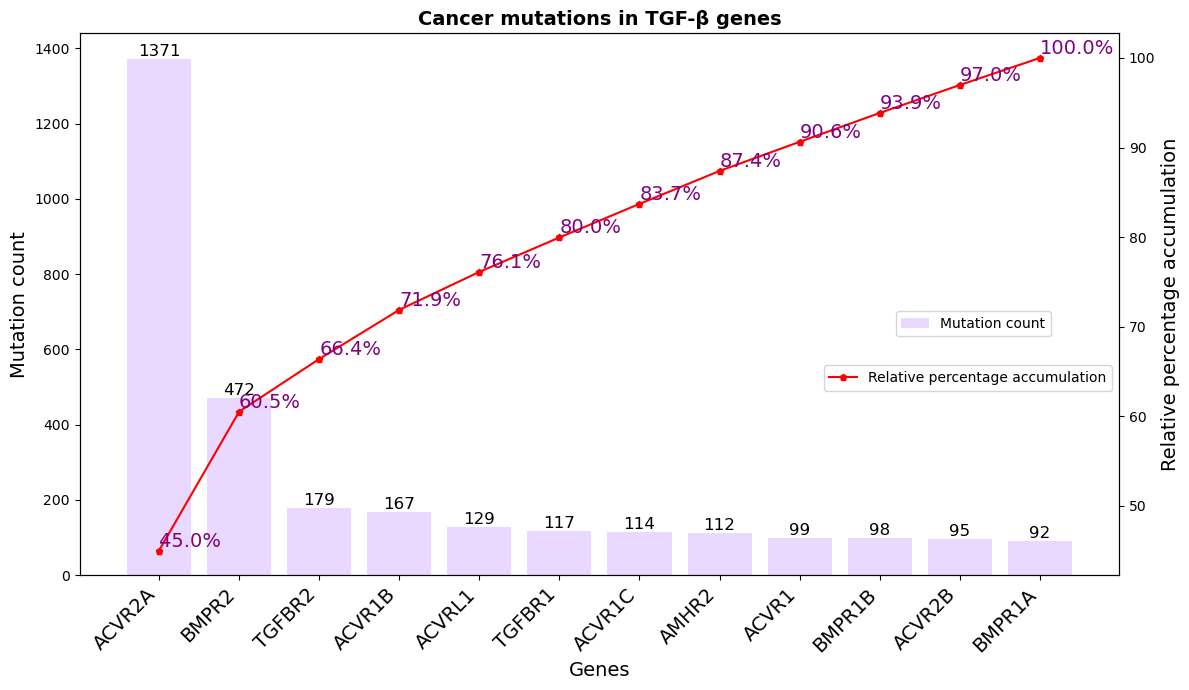

In [3]:
#GENERAL PARAMETERS
df = maf_genes 
count = "HGVSp_Short" 
grupo = "Hugo_Symbol" 
mutation_counts = df.groupby(grupo, as_index=False)[count].count() 

#LABEL PARAMETERS
ylabel = 'Mutation count' # label axis y
ylabel2 = 'Relative percentage accumulation' # label axis y2
set_title = 'Cancer mutations in TGF-β genes' # title
set_xlabel = 'Genes' # title axis X
leyenda_2 = 'Relative percentage accumulation' # label axis 2
leyenda_count = 'Mutation count' # label axis 1

#COLORS PARAMETERS
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

# SAVED
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # or svg
DPI = 600 
NOMBRE_IMAGEN = "CancerMut_gene_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"

# Sort from highest to lowest
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calculate the cumulative percentage
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# shape and axes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

#  Bar chart mutation count
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# line cumulative percentage
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Add labels with the number of mutations above the bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Add labels showing the cumulative percentage at points along the line
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14)

# labels
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# label axis x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# add label 
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  

plt.tight_layout()

# save graph
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()

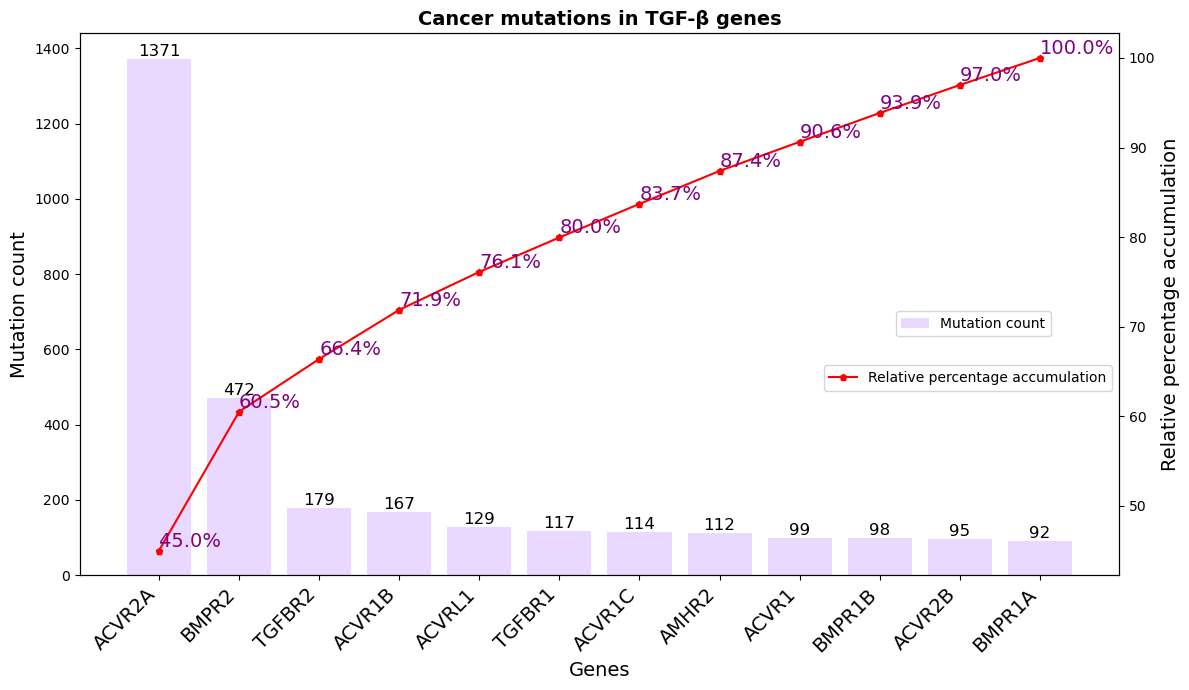

In [3]:
#GENERAL PARAMETERS
df = maf_genes 
count = "HGVSp_Short" 
grupo = "Hugo_Symbol" 
mutation_counts = df.groupby(grupo, as_index=False)[count].count() 

#LABEL PARAMETERS
ylabel = 'Mutation count' # label axis y
ylabel2 = 'Relative percentage accumulation' # label axis y2
set_title = 'Cancer mutations in TGF-β genes' # title
set_xlabel = 'Genes' # title axis X
leyenda_2 = 'Relative percentage accumulation' # label axis 2
leyenda_count = 'Mutation count' # label axis 1

#COLORS PARAMETERS
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

# SAVED
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # or svg
DPI = 600 
NOMBRE_IMAGEN = "CancerMut_gene_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"

# Sort from highest to lowest
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calculate the cumulative percentage
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# shape and axes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

#  Bar chart mutation count
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# line cumulative percentage
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Add labels with the number of mutations above the bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Add labels showing the cumulative percentage at points along the line
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14)

# labels
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# label axis x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# add label 
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  

plt.tight_layout()

# save graph
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()

In [6]:
maf_genes.columns

Index(['Patient_ID', 'Tumor_Sample_Barcode', 'Hugo_Symbol', 'Chromosome',
       'Variant_Classification', 'Variant_Type', 'Reference_Allele',
       'Tumor_Seq_Allele2', 'HGVSc', 'HGVSp_Short', 'HGVSp', 'Project_ID',
       'cancer_type'],
      dtype='object')

In [22]:
mut_df = maf_genes[['Patient_ID','Hugo_Symbol', 'HGVSp_Short']]
mut_df["HGVSp_Short"] = mut_df["HGVSp_Short"].replace("p.?", np.nan)
mut_df.dropna(subset=["HGVSp_Short"], inplace=True)
mut_df

/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_54646/314279491.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mut_df["HGVSp_Short"] = mut_df["HGVSp_Short"].replace("p.?", np.nan)
/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_54646/314279491.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mut_df.dropna(subset=["HGVSp_Short"], inplace=True)


,Patient_ID,Hugo_Symbol,HGVSp_Short
0,TCGA-A6-6781,ACVR2A,K437Rfs*5
1,TCGA-A5-A2K3,ACVR2A,K437Rfs*5
3,TCGA-CG-4306,ACVR2A,K437Rfs*5
5,TCGA-QG-A5Z2,ACVR2A,K437Rfs*5
6,TCGA-VQ-A91E,ACVR2A,K437Rfs*5
...,...,...,...
4052,TCGA-FW-A3R5,ACVR1C,S270L
4056,TCGA-W3-AA1V,BMPR1A,G203E
4060,TCGA-ER-A193,BMPR1A,Q528*
4061,TCGA-D3-A1Q4,AMHR2,M147I


In [37]:
mut_df = mut_df.groupby(["Patient_ID","Hugo_Symbol"])["HGVSp_Short"].count().reset_index()


df_heatmap

Patient_ID,TCGA-05-4382,TCGA-05-4410,TCGA-06-1087,TCGA-06-5416,TCGA-09-2045,TCGA-13-0764,TCGA-13-0884,TCGA-13-0904,TCGA-13-2059,TCGA-14-1396,...,TCGA-YG-AA3O,TCGA-Z6-A8JD,TCGA-Z6-A9VB,TCGA-Z6-AAPN,TCGA-ZF-A9R4,TCGA-ZF-A9RL,TCGA-ZF-AA4N,TCGA-ZF-AA4V,TCGA-ZF-AA4W,TCGA-ZS-A9CE
Hugo_Symbol,,,,,,,,,,,,,,,,,,,,,
ACVR1,NaN,NaN,NaN,1.0,NaN,NaN,1.0,1.0,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
ACVR1B,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
ACVR1C,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ACVR2A,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
ACVR2B,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ACVRL1,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AMHR2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BMPR1A,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BMPR1B,1.0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN


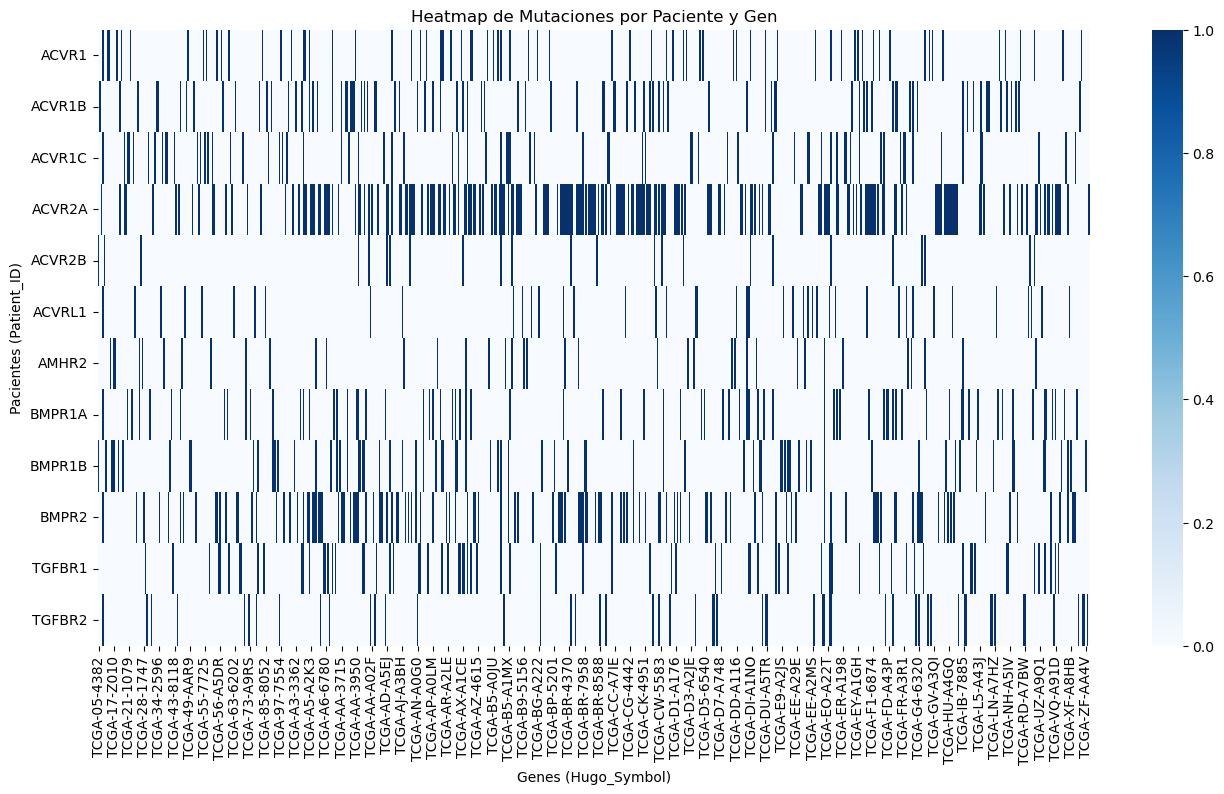

In [48]:
import seaborn as sns

df_heatmap = mut_df.pivot_table(
    index='Hugo_Symbol', 
    columns='Patient_ID', 
    values='HGVSp_Short',
)

# 2. Rellenamos los espacios vacíos (los pacientes que no tienen mutación en ese gen) con 0
df_heatmap = df_heatmap.fillna(0)

# Opcional: Convertir a entero para que se vea más limpio (0 y 1)
df_heatmap = df_heatmap.astype(int)

# --- BONUS: Cómo graficar tu Heatmap ---
plt.figure(figsize=(16, 8))
sns.heatmap(
    df_heatmap, 
    cmap="Blues",       # Color azul (Blanco = 0, Azul Oscuro = 1)
    cbar=True,          # Forzamos que se muestre la barra de color a la derecha  # Quitamos las líneas para que no borren el color si la matriz es gigante
)
plt.title("Heatmap de Mutaciones por Paciente y Gen")
plt.ylabel("Pacientes (Patient_ID)")
plt.xlabel("Genes (Hugo_Symbol)")
plt.show()

In [ ]:
fig, axs = plt.subplot_mosaic([['histx', '.'],
                               ['scatter', 'histy']],
                              figsize=(6, 6),
                              width_ratios=(4, 1), height_ratios=(1, 4),
                              layout='constrained')
scatter_hist(x, y, axs['scatter'], axs['histx'], axs['histy'])